# Demo phân loại ảnh thời trang bằng CNN

**Trình bày trong 5–7 phút.** Đầu vào là ảnh xám 28×28 của Fashion-MNIST. Đầu ra là một trong 10 lớp trang phục. Ta sẽ cho ba mô hình dự đoán cùng ảnh, quan sát đặc trưng CNN rồi đối chiếu kết quả trên toàn bộ tập test.

Mở thư mục dự án trong VS Code, chọn kernel Python của `.venv` và chạy từ trên xuống. Checkpoint phải có trong `models/checkpoints`. Demo chạy inference trên CPU với trọng số đã huấn luyện trên Colab. Nếu thiếu kernel Jupyter, dùng lệnh chạy offline trong [hướng dẫn demo](../demo/README.md).

## 1. Chuẩn bị đường dẫn

Tìm thư mục gốc để notebook dùng chung mã dự đoán, checkpoint, ảnh mẫu và kết quả đã lưu.

In [1]:
import csv
import sys
from pathlib import Path

current = Path.cwd()
project = next(
    (path for path in (current, *current.parents) if (path / "demo/present.py").is_file()),
    None,
)
if project is None:
    raise RuntimeError("Mở thư mục dự án trong VS Code rồi chạy lại ô này.")
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

from matplotlib import pyplot as plt
from demo.present import render_sample

report = project / "reports" / "results" / "20261104"
print("Sẵn sàng chạy dự đoán CPU.")

Sẵn sàng chạy dự đoán CPU.


## 2. Dự đoán cùng một ảnh

Ảnh **#183** có nhãn thật là **Shirt**. MLP trải phẳng ảnh thành 784 giá trị. CNN học các mẫu cục bộ bằng bộ lọc dùng chung ở nhiều vị trí. Hãy chỉ vào bảng để xem ba mô hình dự đoán gì. Điểm softmax là điểm cho từng lớp trên ảnh đang xem.

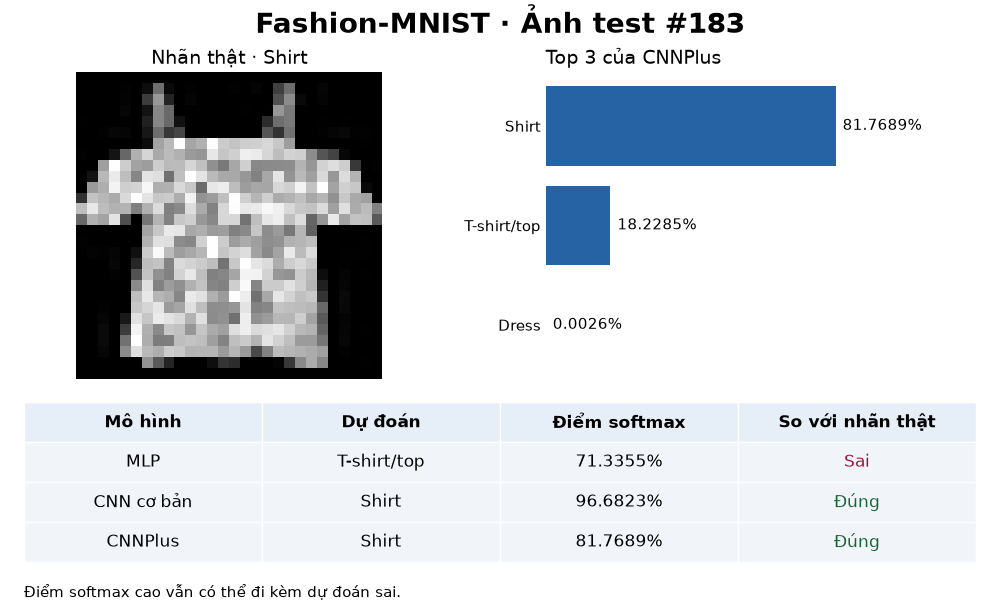

In [2]:
sample_id = 183
render_sample(sample_id)
plt.show()

## 3. Cho thấy mô hình cũng có thể sai

Ở ảnh **#2914**, nhãn thật là **Sneaker**. Hãy để người xem đoán trước, rồi chạy ô dưới để đối chiếu. Dù điểm cao, CNNPlus vẫn có thể xếp nhầm lớp. Hai ảnh này được chọn để minh họa.

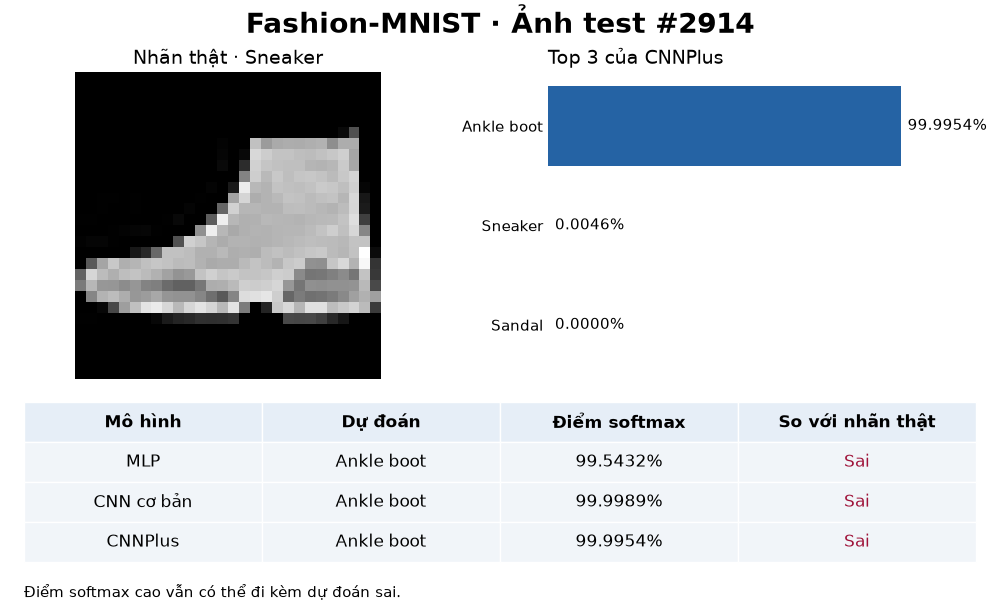

In [3]:
render_sample(2914)
plt.show()

## 4. Quan sát đặc trưng do CNN học

`ToTensor` và chuẩn hóa là bước chuẩn bị đầu vào. Hình dưới lấy từ kết quả đã lưu của CNNPlus trên ảnh **#19**, một ảnh T-shirt/top dự đoán đúng. Mỗi ô là một kênh kích hoạt. Tầng đầu còn 28×28, tầng sâu còn 14×14 sau bước pooling trước đó. Mỗi kênh dùng thang màu riêng. Hãy mô tả vùng nào nổi lên và hình thay đổi thế nào qua hai tầng.

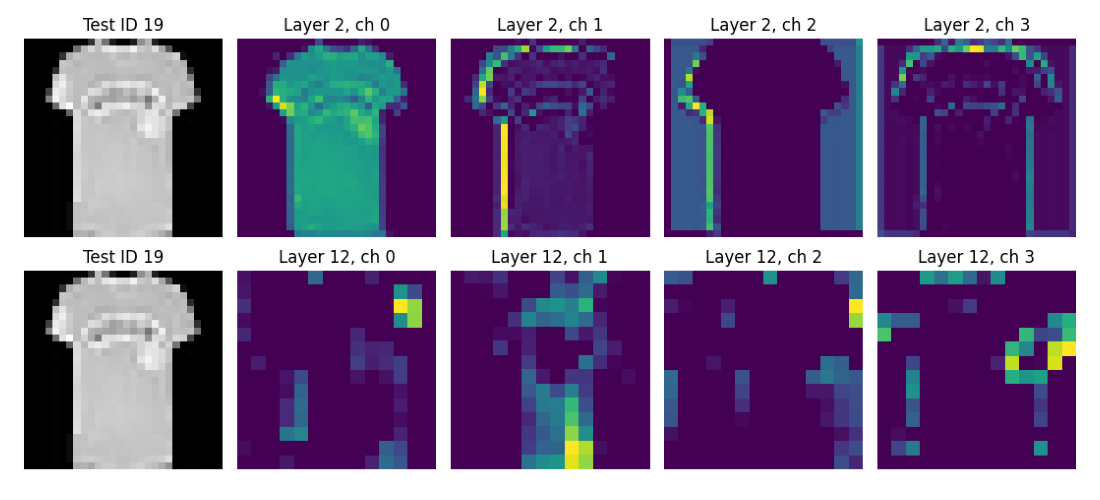

In [4]:
fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
ax.imshow(plt.imread(report / "features_19.png"))
ax.axis("off")
plt.show()

## 5. Kết quả trên 10.000 ảnh test

Accuracy là tỷ lệ ảnh dự đoán đúng. Macro-F1 tính F1 từng lớp rồi lấy trung bình. Bản CNNPlus dùng khi demo được chọn bằng tập validation. Ở ma trận, đọc theo hàng nhãn thật và cột nhãn dự đoán. Ví dụ, có **94 ảnh Shirt** bị đoán thành **T-shirt/top**.

MLP       Accuracy 88.55%  Macro-F1 88.55%
CNN       Accuracy 92.11%  Macro-F1 92.09%
CNNPlus   Accuracy 93.70%  Macro-F1 93.66%


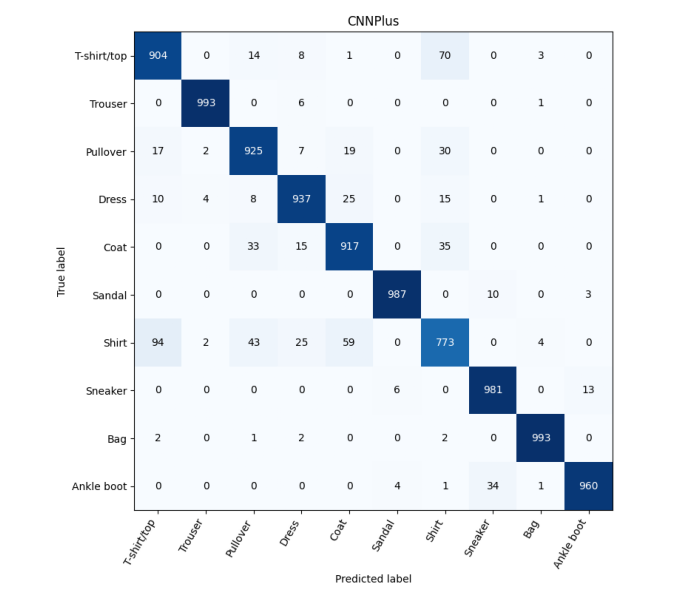

In [5]:
with (report / "test_comparison.csv").open(encoding="utf-8", newline="") as file:
    for row in csv.DictReader(file):
        if row["seed"] == "42":
            accuracy = float(row["accuracy"])
            macro_f1 = float(row["macro_f1"])
            print(f"{row['model']:8}  Accuracy {accuracy:6.2%}  Macro-F1 {macro_f1:6.2%}")

fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
ax.imshow(plt.imread(report / "CNNPlus_confusion.png"))
ax.axis("off")
plt.show()

### Tập trình bày

Đổi `sample_id` ở bước 2 thành **19** rồi chạy lại. Cả ba mô hình đều đoán đúng ảnh này. Dùng bảng 10.000 ảnh ở bước 5 để kết luận về chất lượng chung.